<a href="https://colab.research.google.com/github/pranav-1205/CSL701-Roll_No_CS47_Machine-Learning-Lab/blob/main/Experiments/ML_Experiment_8_Minimum_Spanning_Tree_(MST).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Machine Learning Experiment Number 8


Student Name : Pranav Vivek Sadwelkar

Batch : CS 03


Roll Number : CS 47



### **Aim**

To implement graph-based clustering using Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset in Python and visualize the resulting clusters.

## Objectives

1. To understand the concept of graph-based clustering and Minimum Spanning Trees (MST).
2. To load and preprocess the Breast Cancer Wisconsin dataset (scaling features and handling metadata).
3. To construct a distance graph from tumor feature representations using Euclidean distance.
4. To compute the Minimum Spanning Tree using Prim's or Kruskal's algorithm (or via scipy/networkx).
5. To form K = 2 clusters (Malignant vs. Benign) by removing the single (K - 1) largest edge weight from the MST.
6. To evaluate the performance of the MST-based clustering model using evaluation metrics.

# Relevant Theory

###Graph-Based Clustering & Minimum Spanning Tree (MST)
Graph-based clustering represents data points as nodes in a graph, with edges representing relationships or distance metrics between individual samples.
* **Complete Graph Construction**: Given a dataset X = {x1, x2, ..., xn},
each tissue sample is treated as a vertex. An edge weight `w(i, j)` corresponds to the distance between sample i and sample j (typically Euclidean distance on scaled features):

`w(i, j) = ||x_i - x_j||_2`


* **Minimum Spanning Tree (MST)**: An MST is a subset of edges connecting all vertices in the graph without forming any cycles, while minimizing the total edge weight sum.
* **MST-Based Clustering Method**:
  1. Construct a fully connected graph with pairwise edge weights across standardized features.
  2. Compute the Minimum Spanning Tree (MST).
  3. To partition the data into K distinct clusters (such as Malignant and Benign groups), identify and remove the K - 1 largest (most expensive) edges from the MST.
  4. The resulting disconnected subgraphs represent the separate data clusters.

### Dataset Information
Get the Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle or via scikit-learn (load_breast_cancer).
The dataset contains key cell nuclei features computed from digitized images of fine needle aspirates (FNA) of breast masses:
  * Total Instances: 569 samples
  * Target Classes: Malignant (M) and Benign (B)
  * Feature Attributes: 30 numerical features (e.g., mean radius, mean texture, mean perimeter, mean area, mean smoothness)

For 2D visualization, two key features (such as mean radius and mean texture) will be selected.

# Task 1: Import Libraries and Load Dataset

* Import required libraries (numpy, pandas, matplotlib, scipy, networkx, sklearn).

* Load the Breast Cancer dataset using below link from Kaggle.

  https://www.kaggle.com/datasets/utkarshx27/breast-cancer-wisconsin-diagnostic-dataset

---

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score


df = pd.read_csv("brca.csv")

# This Kaggle version prefixes feature names with "x." and calls the label "y"
df.columns = [c.replace("x.", "") for c in df.columns]

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (569, 32)


,Unnamed: 0,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_pts_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_pts_worst,symmetry_worst,fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


# Task 2: Explore the Dataset

* Display missing value checks, summary statistics, and feature dimensions.

* Check the diagnosis class distribution (Malignant vs. Benign).

Missing values: 0

Data types:
 float64    30
int64       1
object      1
Name: count, dtype: int64

Number of features: 30 (excluding the index column and the label y)


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
concave_pts_mean,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
fractal_dim_mean,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744



Diagnosis distribution:
y
B    357
M    212
Name: count, dtype: int64


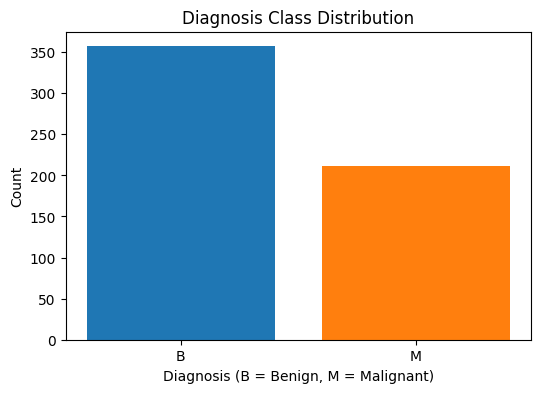

In [3]:
X_preview = df.drop(columns=["Unnamed: 0", "y"])
print("Missing values:", int(df.isnull().sum().sum()))
print("\nData types:\n", df.dtypes.value_counts())
print("\nNumber of features:", df.shape[1] - 2, "(excluding the index column and the label y)")
display(X_preview.describe().T.head(10))

counts = df["y"].value_counts()
print("\nDiagnosis distribution:")
print(counts)

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color=["tab:blue", "tab:orange"])
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Count")
plt.title("Diagnosis Class Distribution")
plt.show()

# Task 3: Preprocess and Scale Features

* Select numerical features and drop non-informative identifiers (such as id).

* Apply StandardScaler to normalize feature magnitudes prior to graph distance calculation.

In [4]:
# Drop the identifier/index column and separate features from the label
X = df.drop(columns=["Unnamed: 0", "y"])
y = df["y"].map({"B": 0, "M": 1}).values      # ground truth, used ONLY for evaluation

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature matrix shape:", X_scaled.shape)
print("Feature means (first 3):", X_scaled.mean(axis=0)[:3].round(6))
print("Feature std   (first 3):", X_scaled.std(axis=0)[:3].round(6))

Feature matrix shape: (569, 30)
Feature means (first 3): [-0. -0. -0.]
Feature std   (first 3): [1. 1. 1.]


# Task 4: Construct Pairwise Distance Matrix & Graph

* Compute pairwise Euclidean distance matrix across all scaled samples using scipy.spatial.distance.pdist or cdist.

* Represent the dataset as a weighted complete graph.

In [5]:
# Pairwise Euclidean distances -> weighted complete graph (569 vertices)
dist_matrix = squareform(pdist(X_scaled, metric="euclidean"))

n = dist_matrix.shape[0]
print("Distance matrix shape:", dist_matrix.shape)
print("Number of vertices   :", n)
print("Number of edges in the complete graph:", n * (n - 1) // 2)
print("Smallest / largest pairwise distance:",
      round(pdist(X_scaled).min(), 3), "/", round(pdist(X_scaled).max(), 3))

Distance matrix shape: (569, 569)
Number of vertices   : 569
Number of edges in the complete graph: 161596
Smallest / largest pairwise distance: 1.006 / 26.882


# Task 5: Compute the Minimum Spanning Tree (MST)

* Compute the MST using scipy.sparse.csgraph.minimum_spanning_tree or networkx.minimum_spanning_tree.

* Extract the resulting graph connections and weights.

In [6]:
# Minimum Spanning Tree of the complete graph
mst = minimum_spanning_tree(dist_matrix).toarray()

rows, cols = np.nonzero(mst)
weights = mst[rows, cols]

print("MST edges   :", len(weights), "(a tree on", n, "vertices has", n - 1, "edges)")
print("Total weight:", round(weights.sum(), 3))
print("\nFive heaviest MST edges (u, v, weight):")
for k in np.argsort(weights)[::-1][:5]:
    print(f"  ({rows[k]:3d}, {cols[k]:3d})  {weights[k]:.3f}")
# Cross-check with networkx (Kruskal's algorithm) - should give the same MST weight
G = nx.from_numpy_array(dist_matrix)
mst_nx = nx.minimum_spanning_tree(G, algorithm="kruskal")
nx_weight = mst_nx.size(weight="weight")
print("\nnetworkx MST edges   :", mst_nx.number_of_edges())
print("networkx MST weight  :", round(nx_weight, 3))
print("Matches SciPy result :", np.isclose(nx_weight, weights.sum()))


MST edges   : 568 (a tree on 569 vertices has 568 edges)
Total weight: 1393.852

Five heaviest MST edges (u, v, weight):
  (544, 553)  12.300
  ( 18,  69)  10.476
  ( 48, 468)  8.826
  (467, 544)  8.269
  (424, 429)  8.078

networkx MST edges   : 568
networkx MST weight  : 1393.852
Matches SciPy result : True


# Task 6: Implement Graph-Based Clustering (K = 2)

* Sort the edges of the MST in descending order by edge weight.
* Remove the largest K - 1 edge (1 largest edge for 2 clusters) to split the MST into 2 connected components.
* Assign final cluster labels based on the resulting component indices.


In [7]:
K = 2

# Sort MST edges in descending order of weight and remove the K-1 largest
order = np.argsort(weights)[::-1]
mst_cut = mst.copy()
for k in order[:K - 1]:
    mst_cut[rows[k], cols[k]] = 0
    print(f"Removed edge ({rows[k]}, {cols[k]}) with weight {weights[k]:.3f}")

# Connected components of the cut tree = clusters
n_clusters, labels = connected_components(mst_cut, directed=False)

print("\nNumber of clusters:", n_clusters)
print("Cluster sizes     :", np.bincount(labels))
print("\nCluster vs true diagnosis:")
display(pd.crosstab(pd.Series(labels, name="MST cluster"),
                    pd.Series(np.where(y == 1, "Malignant", "Benign"), name="Diagnosis")))

Removed edge (544, 553) with weight 12.300

Number of clusters: 2
Cluster sizes     : [567   2]

Cluster vs true diagnosis:


Diagnosis,Benign,Malignant
MST cluster,,
0,357,210
1,0,2


# Task 7: Evaluate MST Clustering Performance

Evaluate cluster assignment against ground truth labels using:

  *  Silhouette Score

  *  Adjusted Rand Index (ARI)

  *  Normalized Mutual Information (NMI)

In [8]:
sil = silhouette_score(X_scaled, labels)
ari = adjusted_rand_score(y, labels)
nmi = normalized_mutual_info_score(y, labels)

print(f"Silhouette Score            : {sil:.4f}")
print(f"Adjusted Rand Index (ARI)   : {ari:.4f}")
print(f"Normalized Mutual Info (NMI): {nmi:.4f}")

Silhouette Score            : 0.6607
Adjusted Rand Index (ARI)   : 0.0048
Normalized Mutual Info (NMI): 0.0102


# Task 8: Visualize MST and Graph-Based Clusters

* Select two representative features (e.g., mean radius vs. mean texture) for 2D plotting.
 * Plot 1: Unclustered standardized data points.
* Plot 2: Minimum Spanning Tree (MST) edge connections overlaid on the data.
* Plot 3: Final clusters formed after cutting the K - 1 largest edge(s).

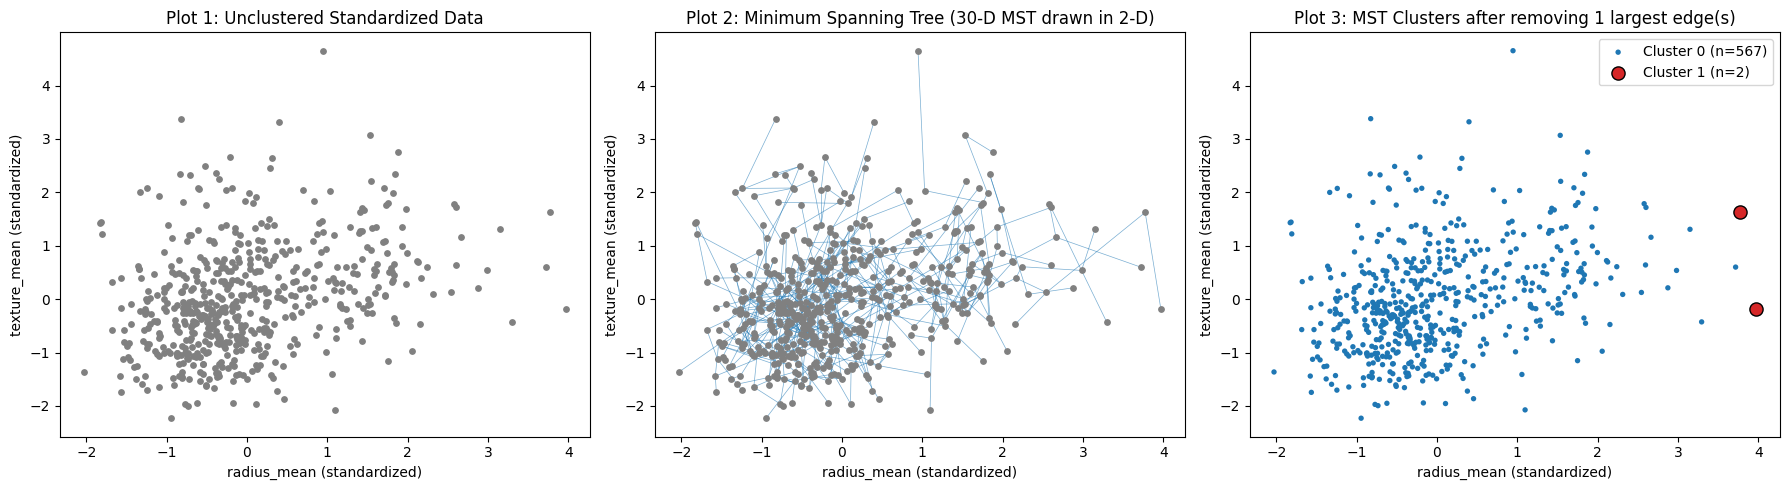

In [9]:
# Plot using two representative features (standardized): radius_mean vs texture_mean
f1, f2 = list(X.columns).index("radius_mean"), list(X.columns).index("texture_mean")
P = X_scaled[:, [f1, f2]]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: unclustered data
axes[0].scatter(P[:, 0], P[:, 1], s=15, color="gray")
axes[0].set_title("Plot 1: Unclustered Standardized Data")

# Plot 2: MST edges overlaid (the MST itself was computed in all 30 dimensions)
axes[1].scatter(P[:, 0], P[:, 1], s=15, color="gray", zorder=2)
for u, v in zip(rows, cols):
    axes[1].plot([P[u, 0], P[v, 0]], [P[u, 1], P[v, 1]], color="tab:blue", lw=0.5, alpha=0.6, zorder=1)
axes[1].set_title("Plot 2: Minimum Spanning Tree (30-D MST drawn in 2-D)")

# Plot 3: clusters after cutting the K-1 largest edge(s)
palette = ["tab:blue", "tab:red", "tab:green", "tab:orange"]
for c in range(n_clusters):
    m = labels == c
    axes[2].scatter(P[m, 0], P[m, 1], s=15 if m.sum() > 10 else 90, color=palette[c],
                    edgecolor="k" if m.sum() <= 10 else "none",
                    label=f"Cluster {c} (n={m.sum()})")
axes[2].set_title(f"Plot 3: MST Clusters after removing {K - 1} largest edge(s)")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("radius_mean (standardized)")
    ax.set_ylabel("texture_mean (standardized)")
plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of Graph-Based Clustering using a Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset. The dataset was preprocessed, cleaned, and standardized before computing pairwise distances. The MST was generated, and by removing the largest edge(s), clusters representing tumor categories were obtained, evaluated using clustering metrics, and visualized.